# Errori di predizione

Dove sbaglia il modello? Per una sequenza del validation mostra gli stessi pannelli di `01_visualize_sequences` più, per **t0** e **t1**: target vero, predizione e errore. In fondo, l'analisi degli errori su tutto il validation.

**Calibrazione.** La loss Pearson non fissa la scala delle predizioni (media e ampiezza diverse dai target). Per rendere l'errore leggibile ogni target viene calibrato con una retta `a·p + b`, stimata con gli stessi pesi `|y|` della metrica su tutto il validation. La correlazione, e quindi il punteggio, **non cambia**.

**Errore** = `clip(pred calibrata) − clip(target)`, entrambi in `[-2, 2]` come nella metrica. Le bande verdi sono le righe `is_scored`, quelle grigie il warm-up.

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

STUDIES = Path.cwd() if (Path.cwd() / 'seqviz.py').exists() else Path.cwd() / 'studies'
sys.path[:0] = [str(STUDIES), str(STUDIES / 'lstm')]
from seqviz import VALID, WARMUP, TRADE_COLORS, load_sequence, shade_mask
import data
from models import load_model

# modello da analizzare: 'baseline' (GRU ufficiale) oppure un checkpoint, es. 'lstm/runs/lstm_h128_l2/best.pt'
RUN = 'lstm/runs/lstm_h128_l2/best.pt'
#RUN = 'baseline'


plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['axes.grid'] = True

## Predizioni su tutto il validation
Il modello gira su GPU (se disponibile) su tutte le 1.873 sequenze: pochi secondi.

In [13]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = load_model(RUN, device)

va = data.load('valid')                       # cache in /dev/shm (si crea da sola se manca)
Y = np.asarray(va['Y'])                       # (1873, 20000, 2)
SCORED = np.asarray(va['scored'])             # (1873, 20000)
SEQ_IX = np.asarray(va['seq'])

P_raw = np.empty_like(Y)
with torch.no_grad():
    for b in range(0, len(Y), 128):
        x = torch.from_numpy(np.asarray(va['X'][b:b + 128], dtype=np.float32)).to(device)
        state = None
        for s in range(0, x.shape[1], 2000):
            p, state = model(x[:, s:s + 2000], state)
            P_raw[b:b + 128, s:s + 2000] = p.cpu().numpy()

NEED = np.zeros_like(SCORED)
NEED[:, WARMUP:] = True
print(f'modello: {RUN}')

/mnt/shared_volume/wnn_connectome_starterpack/studies/models.py:61: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  model.head.bias.copy_(torch.from_numpy(weights['reg_head.bias']))


modello: baseline


In [14]:
def weighted_pearson(y, p):
    y, p = np.clip(y, -2, 2).astype(np.float64), np.clip(p, -2, 2).astype(np.float64)
    w = np.abs(y)
    if w.sum() < 1e-8:
        return np.nan
    yc, pc = y - np.average(y, weights=w), p - np.average(p, weights=w)
    den = np.sqrt(np.sum(w * yc**2) * np.sum(w * pc**2))
    return np.sum(w * yc * pc) / den if den > 1e-12 else 0.0


def calibrate(y, p):
    """Retta a·p + b ai minimi quadrati pesati con |clip(y)|."""
    y = np.clip(y, -2, 2)
    a, b = np.polyfit(p, y, 1, w=np.sqrt(np.abs(y)))
    return a, b


mask = NEED & SCORED
CAL = [calibrate(Y[..., k][mask], P_raw[..., k][mask]) for k in range(2)]
P = np.stack([CAL[k][0] * P_raw[..., k] + CAL[k][1] for k in range(2)], axis=-1)
ERR = np.clip(P, -2, 2) - np.clip(Y, -2, 2)

for k in range(2):
    print(f't{k}: calibrazione a={CAL[k][0]:.3f} b={CAL[k][1]:+.3f}  |  '
          f'WP grezza {weighted_pearson(Y[..., k][mask], P_raw[..., k][mask]):.4f}  '
          f'WP calibrata {weighted_pearson(Y[..., k][mask], P[..., k][mask]):.4f}')

t0: calibrazione a=0.330 b=-0.871  |  WP grezza 0.5879  WP calibrata 0.6687
t1: calibrazione a=0.323 b=-0.549  |  WP grezza 0.6462  WP calibrata 0.6781


## Grafico di una sequenza: target, predizione, errore

In [15]:
def plot_prediction(group, start=0, end=None, show_trade=False, show_i1=False, show_price=True):
    df = load_sequence(VALID, group=group)
    d = df.iloc[start:end]
    steps = d['step_in_seq'].to_numpy()
    sl = slice(start, end)
    panels = (['price'] if show_price else []) + ['t0', 't1', 'err'] \
        + (['dp', 'dv'] if show_trade else []) + (['i1'] if show_i1 else [])
    ratios = {'price': 1.6, 't0': 1.4, 't1': 1.4, 'err': 1.2, 'dp': 1.1, 'dv': 0.9, 'i1': 0.9}
    fig, axes = plt.subplots(len(panels), 1, sharex=True,
                             gridspec_kw={'height_ratios': [ratios[p] for p in panels]},
                             figsize=(16, 2.9 * len(panels) + 1))
    ax_of = dict(zip(panels, axes))

    if show_price:
        ax = ax_of['price']
        ax.plot(steps, d['i0_bid'], lw=1.2, color='tab:blue', label='i0 bid (media p0–p10)')
        ax.plot(steps, d['i0_ask'], lw=1.2, color='tab:red', label='i0 ask (media p11–p21)')
        ax.plot(steps, d['i0_mid'], lw=1.5, color='black', label='i0 mid')
        ax.set_ylabel('prezzo (normalizzato)')
        ax.legend(loc='upper left', fontsize=9)

    for k, color in ((0, 'tab:green'), (1, 'tab:purple')):
        ax = ax_of[f't{k}']
        ax.plot(steps, Y[group, sl, k], lw=1.4, color=color, label=f't{k} vero')
        ax.plot(steps, P[group, sl, k], lw=1.4, color='black', alpha=0.8, label=f't{k} predetto (calibrato)')
        ax.axhline(0, color='grey', lw=0.6)
        for y in (-2, 2):
            ax.axhline(y, color='grey', lw=0.6, ls='--')
        ax.set_ylabel(f't{k}')
        ax.legend(loc='upper left', fontsize=9)

    ax = ax_of['err']
    ax.plot(steps, ERR[group, sl, 0], lw=1.2, color='tab:green', label='errore t0')
    ax.plot(steps, ERR[group, sl, 1], lw=1.2, color='tab:purple', alpha=0.8, label='errore t1')
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_ylabel('pred − vero')
    ax.legend(loc='upper left', fontsize=9)

    if show_trade:
        for grp, label in (('dp', 'prezzo trade'), ('dv', 'volume trade')):
            ax = ax_of[grp]
            for k, color in enumerate(TRADE_COLORS):
                ax.plot(steps, d[f'i0_{grp}{k}'], lw=1.1, color=color, alpha=0.8, label=f'i0_{grp}{k}')
            ax.set_ylabel(label)
            ax.legend(loc='upper left', fontsize=9, ncol=4)

    if show_i1:
        ax = ax_of['i1']
        ax.plot(steps, d['i1_mid'], lw=1.2, color='tab:brown', label='i1 mid')
        ax.set_ylabel('prezzo i1')
        ax.legend(loc='upper left', fontsize=9)

    for ax in axes:
        shade_mask(ax, steps, steps < WARMUP, color='grey', alpha=0.2)
        shade_mask(ax, steps, SCORED[group, sl], color='tab:green', alpha=0.12)
    axes[-1].set_xlabel('step_in_seq')

    m = (NEED & SCORED)[group, sl]
    wp = [weighted_pearson(Y[group, sl, k][m], P[group, sl, k][m]) for k in range(2)]
    fig.suptitle(f'group={group}  seq_ix={SEQ_IX[group]}  step {steps[0]}–{steps[-1]}  scored={int(m.sum())}  '
                 f'WP finestra (scored): t0={wp[0]:.3f}  t1={wp[1]:.3f}')
    fig.tight_layout()
    plt.show()

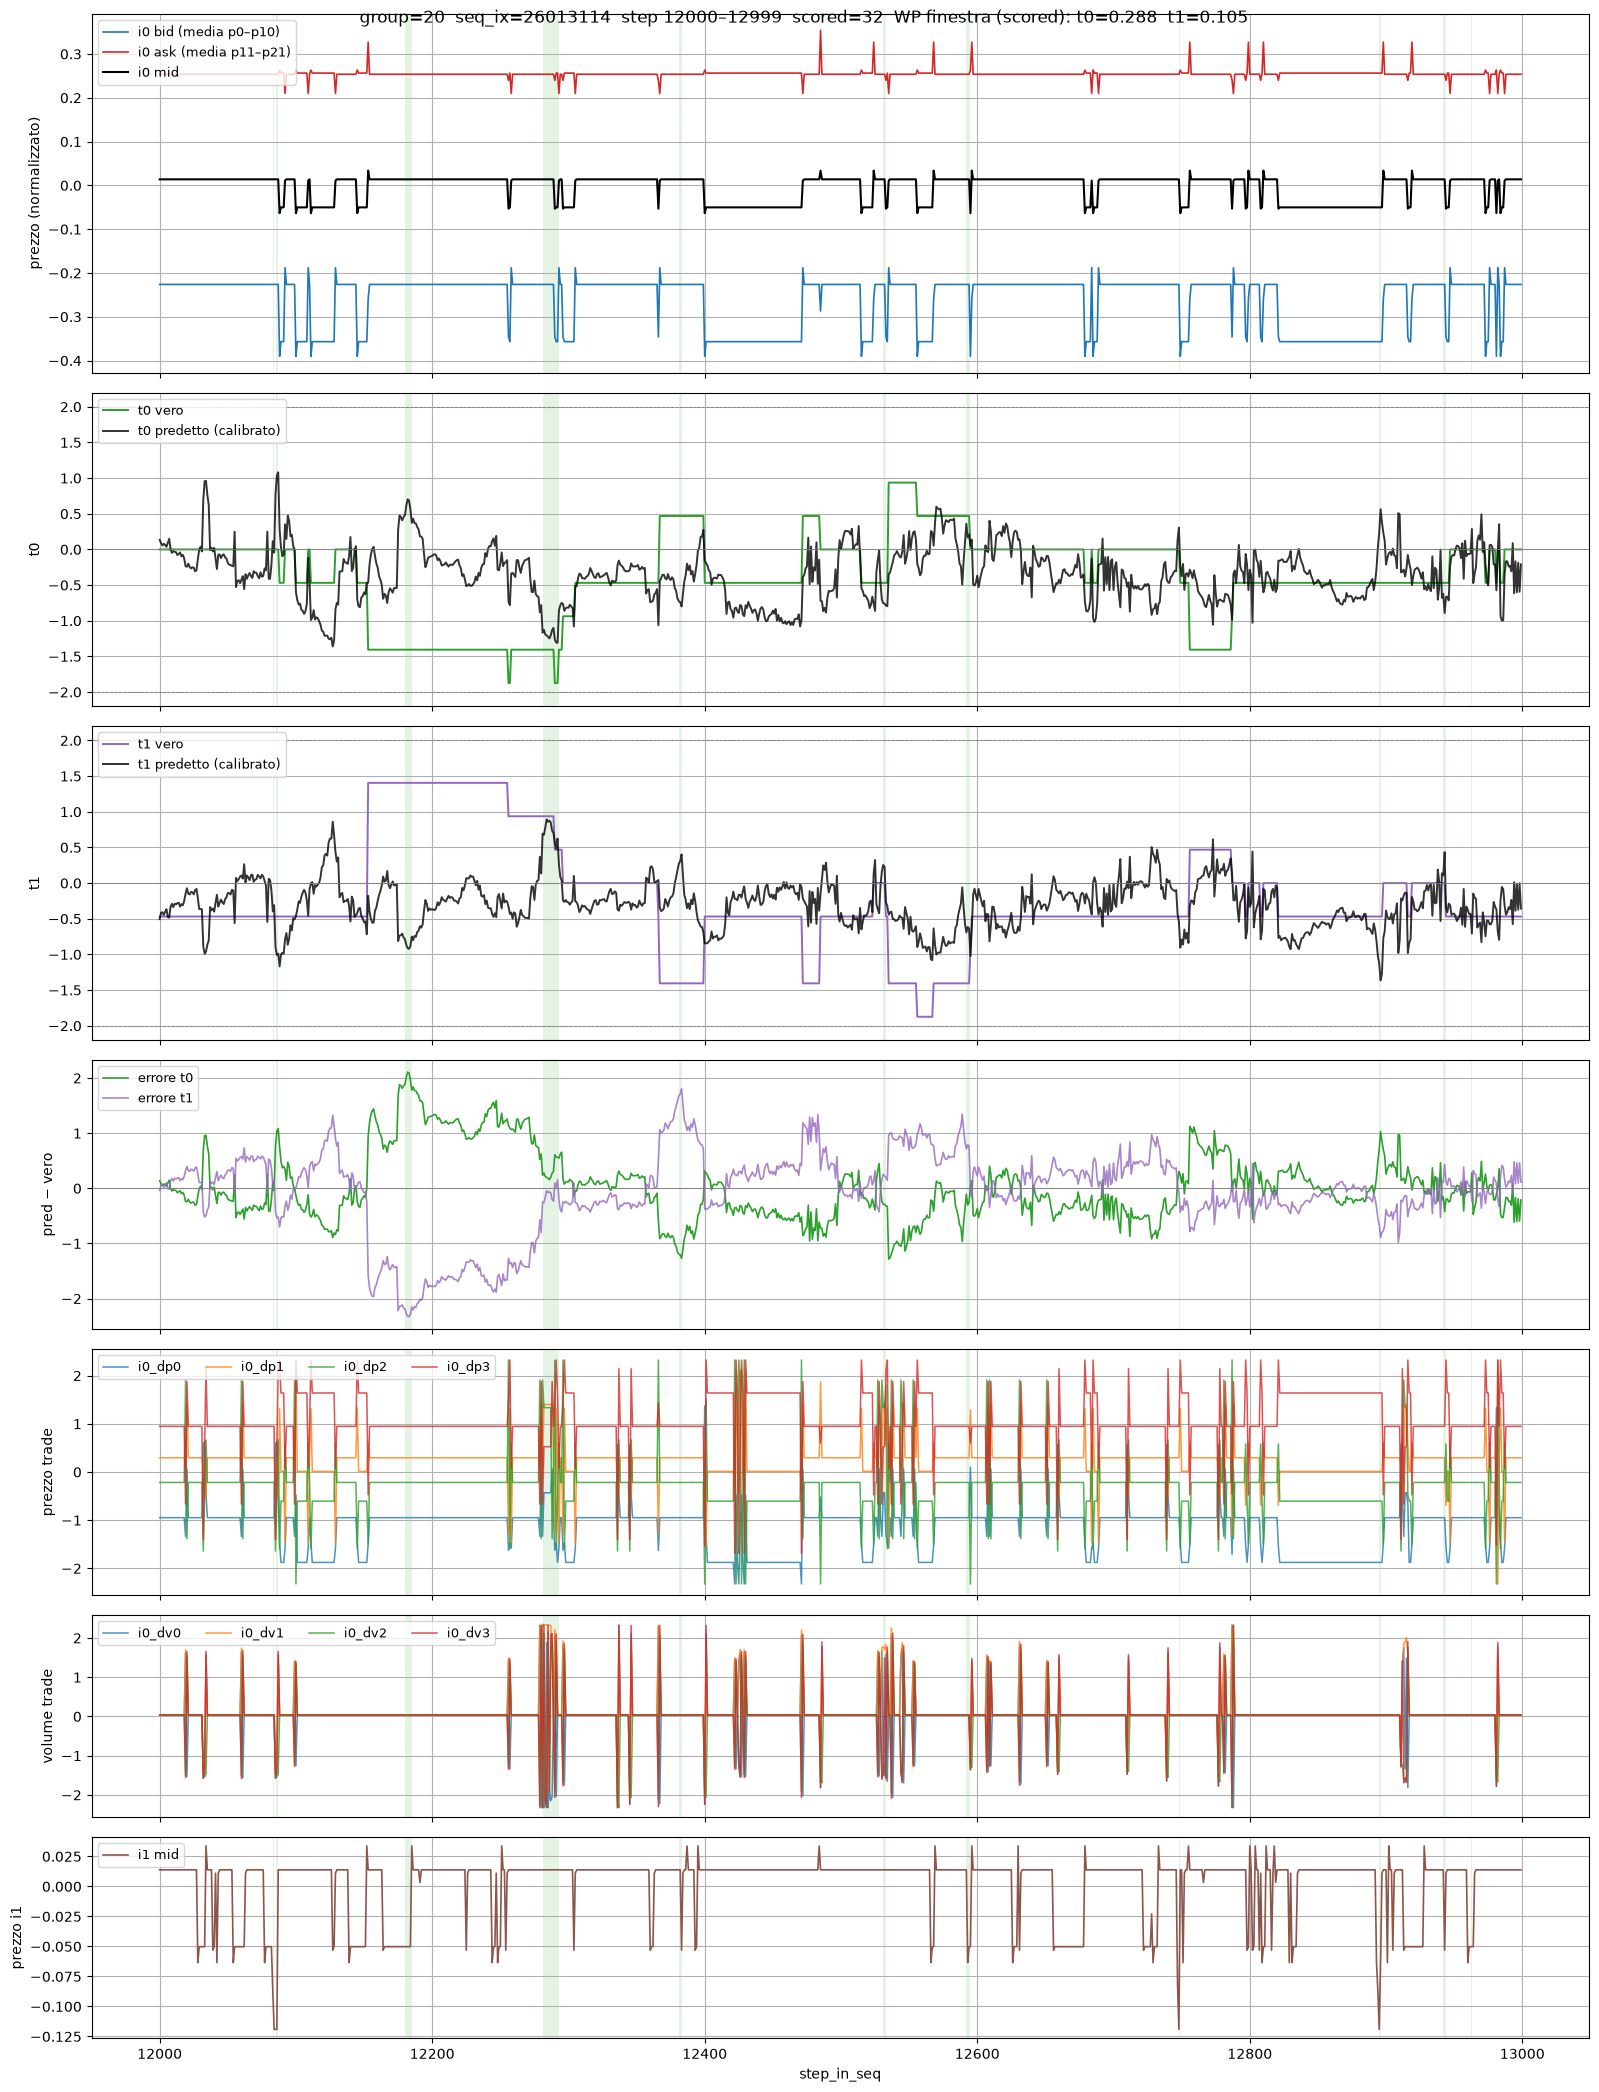

In [16]:
plot_prediction(group=20, start=12000, end=13000, show_trade=True, show_i1=True)

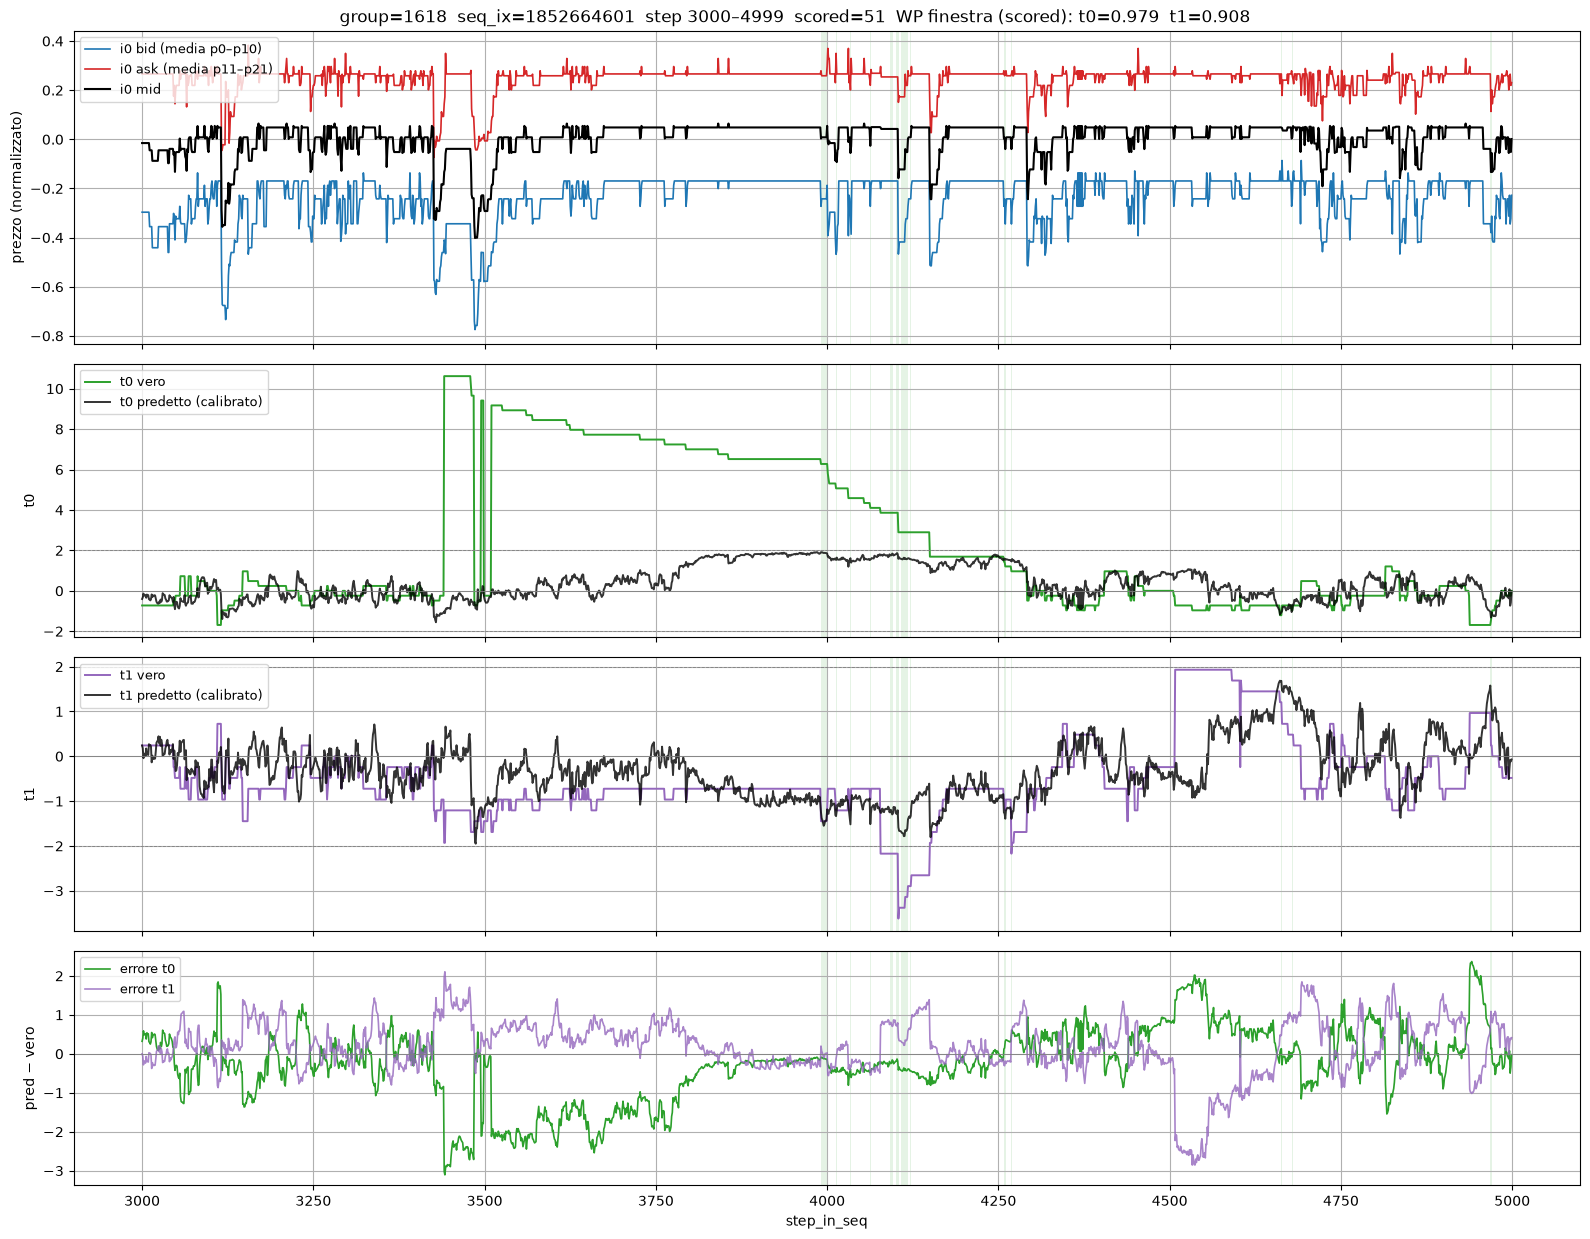

In [26]:
plot_prediction(group=1618, start=3000, end=5000)   # zoom

## Come sono distribuiti gli errori su tutto il validation

### Per sequenza
Global WP calcolata su ogni sequenza separatamente (solo righe `is_scored`). Le sequenze con pochissime righe valutate hanno una stima rumorosa.

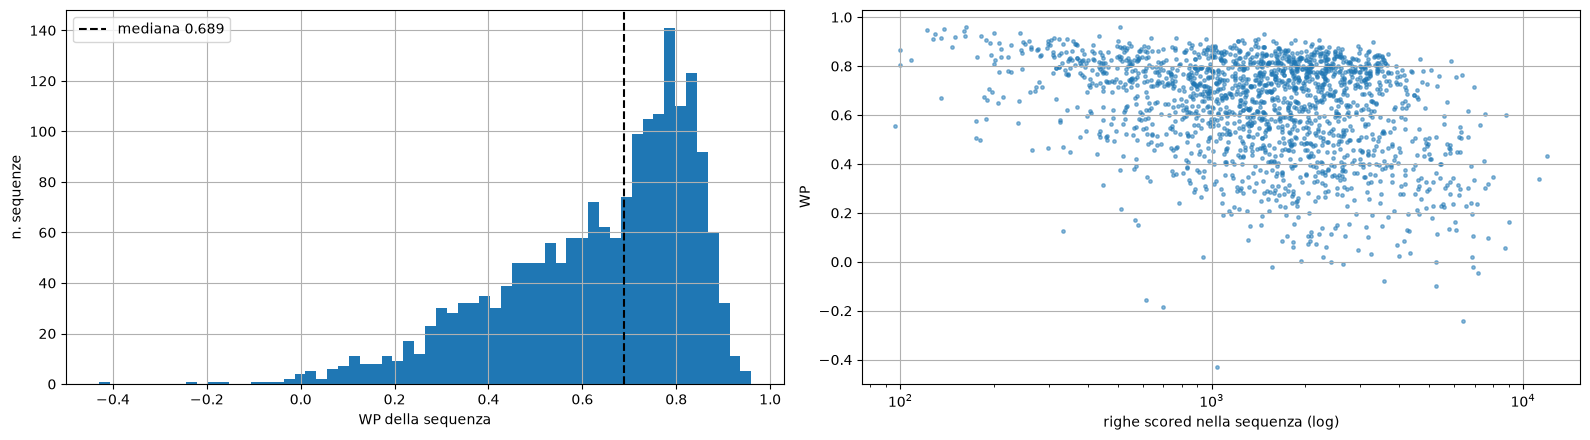

Sequenze peggiori (con almeno 500 righe scored):


,group,seq_ix,scored,wp_t0,wp_t1,mean_abs_target,wp
1009,1009,1159248864,1038,-0.617,-0.244,0.499,-0.430
912,912,1047612114,6423,-0.185,-0.299,0.870,-0.242
251,251,261005563,696,-0.536,0.170,0.467,-0.183
1029,1029,1188821296,614,-0.338,0.023,0.364,-0.158
665,665,754284437,5248,-0.106,-0.091,0.824,-0.098
1203,1203,1392715007,3566,-0.043,-0.114,0.716,-0.078
1118,1118,1287152836,7159,-0.081,-0.007,0.928,-0.044
798,798,929935779,6901,-0.050,0.006,0.883,-0.022
1466,1466,1679975844,1558,-0.082,0.040,0.760,-0.021
906,906,1044111969,2632,0.037,-0.055,0.698,-0.009


Sequenze migliori (con almeno 500 righe scored):


,group,seq_ix,scored,wp_t0,wp_t1,mean_abs_target,wp
1618,1618,1852664601,509,0.974,0.946,1.082,0.960
143,143,143278774,1470,0.910,0.949,1.062,0.930
243,243,249901726,637,0.921,0.910,1.026,0.915
1330,1330,1532494506,765,0.890,0.936,1.080,0.913
578,578,659091070,1405,0.922,0.899,0.881,0.911
112,112,118708188,956,0.907,0.911,0.886,0.909
1590,1590,1817137054,1854,0.904,0.913,0.878,0.909
1268,1268,1475275412,1255,0.901,0.914,0.966,0.908
460,460,519025302,1382,0.903,0.909,0.833,0.906
1018,1018,1174550291,2217,0.915,0.895,0.944,0.905


In [18]:
rows = []
for g in range(len(Y)):
    m = (NEED & SCORED)[g]
    rows.append({'group': g, 'seq_ix': int(SEQ_IX[g]), 'scored': int(m.sum()),
                 'wp_t0': weighted_pearson(Y[g, m, 0], P[g, m, 0]),
                 'wp_t1': weighted_pearson(Y[g, m, 1], P[g, m, 1]),
                 'mean_abs_target': float(np.abs(np.clip(Y[g, m], -2, 2)).mean())})
per_seq = pd.DataFrame(rows)
per_seq['wp'] = per_seq[['wp_t0', 'wp_t1']].mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(per_seq['wp'].dropna(), bins=60, color='tab:blue')
axes[0].axvline(per_seq['wp'].median(), color='black', ls='--', label=f'mediana {per_seq["wp"].median():.3f}')
axes[0].set_xlabel('WP della sequenza'); axes[0].set_ylabel('n. sequenze'); axes[0].legend()
axes[1].scatter(per_seq['scored'], per_seq['wp'], s=6, alpha=0.5)
axes[1].set_xscale('log'); axes[1].set_xlabel('righe scored nella sequenza (log)'); axes[1].set_ylabel('WP')
fig.tight_layout(); plt.show()

print('Sequenze peggiori (con almeno 500 righe scored):')
display(per_seq[per_seq['scored'] >= 500].nsmallest(10, 'wp').round(3))
print('Sequenze migliori (con almeno 500 righe scored):')
display(per_seq[per_seq['scored'] >= 500].nlargest(10, 'wp').round(3))

### Per ampiezza del target
La metrica pesa le righe con `|y|`: gli errori sui movimenti grandi contano di più.

In [19]:
m = NEED & SCORED
bins = [0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.01]
out = []
for k in range(2):
    y = np.clip(Y[..., k][m], -2, 2); p = np.clip(P[..., k][m], -2, 2)
    cat = pd.cut(np.abs(y), bins, include_lowest=True)
    df_k = pd.DataFrame({'|y|': cat, 'abs_err': np.abs(p - y), 'sign_ok': np.sign(p) == np.sign(y),
                         'peso': np.abs(y)})
    g = df_k.groupby('|y|', observed=True).agg(righe=('abs_err', 'size'), errore_medio=('abs_err', 'mean'),
                                               segno_giusto=('sign_ok', 'mean'), peso_totale=('peso', 'sum'))
    g['quota_peso'] = g['peso_totale'] / g['peso_totale'].sum()
    g.insert(0, 'target', f't{k}')
    out.append(g.drop(columns='peso_totale'))
display(pd.concat(out).round(3))

,target,righe,errore_medio,segno_giusto,quota_peso
|y|,,,,,
"(-0.001, 0.25]",t0,1061062,0.510,0.146,0.020
"(0.25, 0.5]",t0,386141,0.573,0.743,0.062
"(0.5, 0.75]",t0,1045891,0.519,0.810,0.281
"(0.75, 1.0]",t0,204199,0.427,0.900,0.073
"(1.0, 1.5]",t0,351543,0.737,0.789,0.184
"(1.5, 2.01]",t0,479437,1.074,0.886,0.380
"(-0.001, 0.25]",t1,1028733,0.534,0.157,0.021
"(0.25, 0.5]",t1,374734,0.557,0.749,0.058
"(0.5, 0.75]",t1,1091827,0.499,0.830,0.288


### Predetto contro vero
Densità delle coppie (target, predizione calibrata) sulle righe `is_scored`. Una diagonale stretta = buone predizioni.

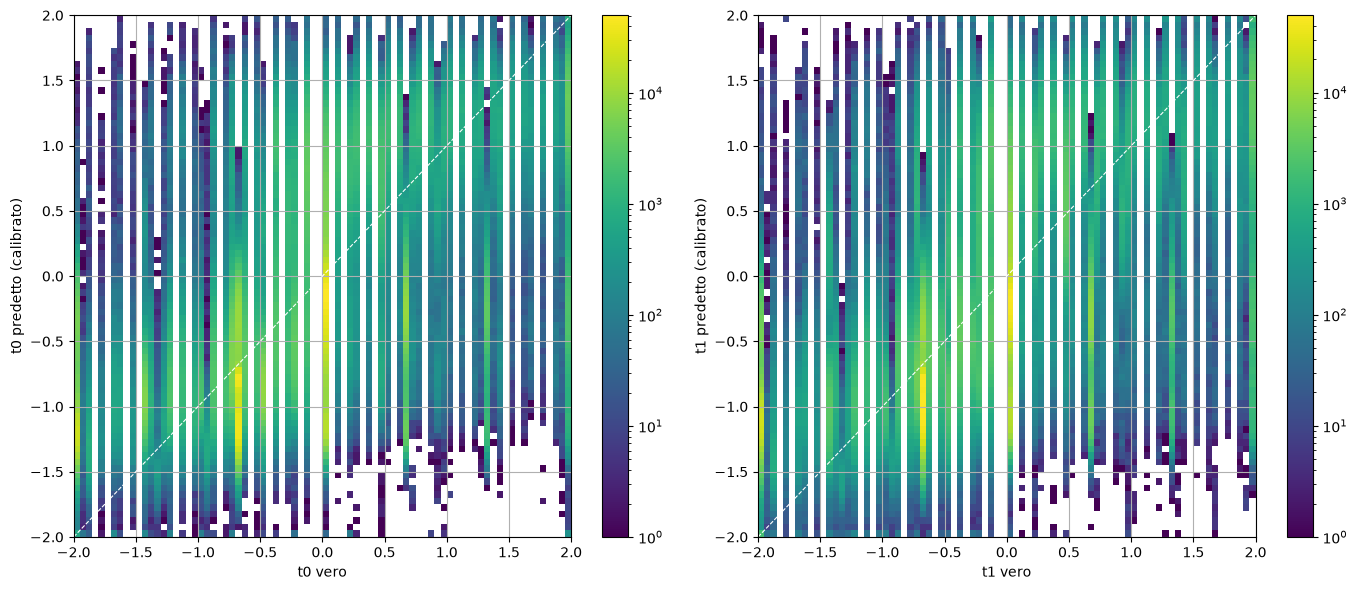

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for k, ax in enumerate(axes):
    y = np.clip(Y[..., k][m], -2, 2); p = np.clip(P[..., k][m], -2, 2)
    h = ax.hist2d(y, p, bins=80, range=[[-2, 2], [-2, 2]], cmap='viridis', norm='log')
    ax.plot([-2, 2], [-2, 2], color='white', lw=0.8, ls='--')
    ax.set_xlabel(f't{k} vero'); ax.set_ylabel(f't{k} predetto (calibrato)')
    fig.colorbar(h[3], ax=ax)
fig.tight_layout(); plt.show()

### Lungo la sequenza
WP per tratti di 1.000 step: righe scored e tutte le righe.

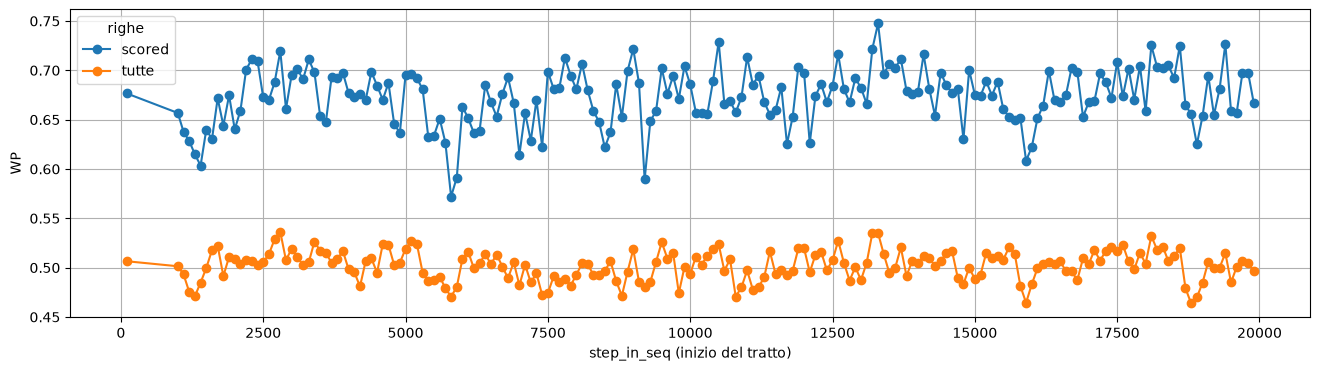

: 

In [ ]:
edges = np.r_[WARMUP, np.arange(1000, 20001, 100)]
res = []
for a, b in zip(edges[:-1], edges[1:]):
    sl = slice(a, b)
    for name, mk in (('scored', (NEED & SCORED)[:, sl]), ('tutte', NEED[:, sl])):
        wp = np.mean([weighted_pearson(Y[:, sl, k][mk], P[:, sl, k][mk]) for k in range(2)])
        res.append({'da': a, 'righe': name, 'wp': wp})
res = pd.DataFrame(res).pivot(index='da', columns='righe', values='wp')
ax = res.plot(marker='o', figsize=(16, 4))
ax.set_xlabel('step_in_seq (inizio del tratto)'); ax.set_ylabel('WP')
plt.show()